First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Data standardized successfully!


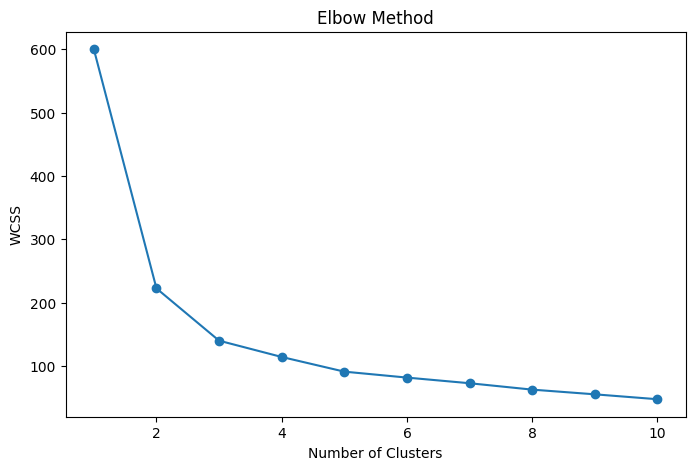


K-Means Cluster Results:
   KMeans_Cluster
0               1
1               1
2               1
3               1
4               1

Number of data points in each K-Means cluster:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64


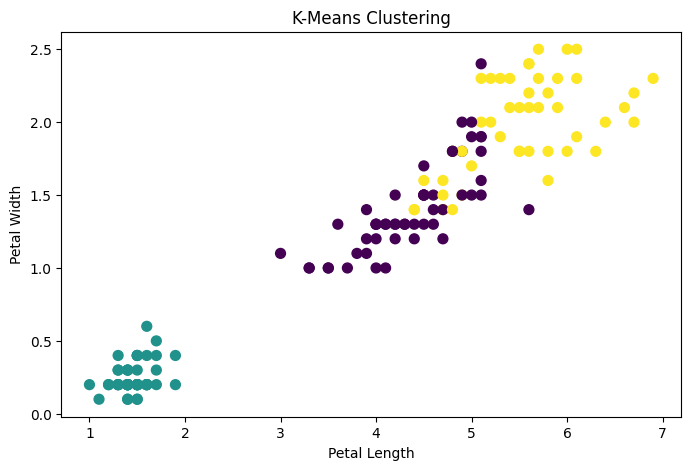

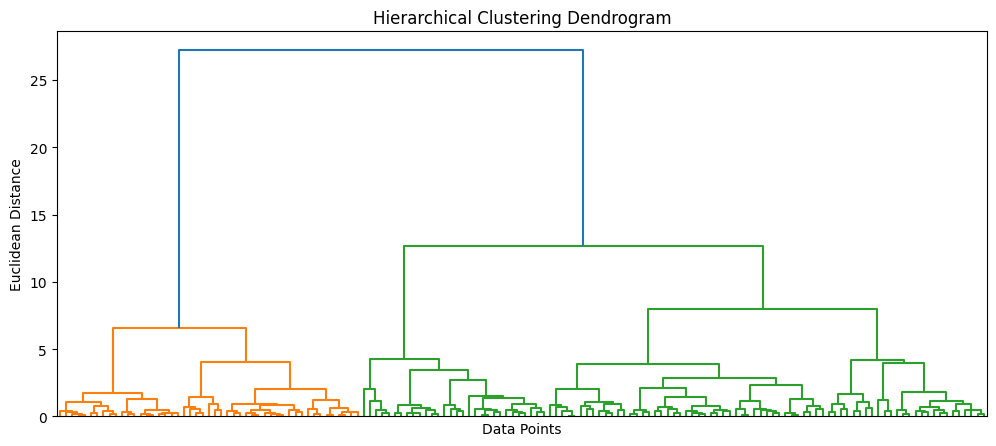


Hierarchical Clustering Results:
   Hierarchical_Cluster
0                     1
1                     1
2                     1
3                     1
4                     1

Number of data points in each Hierarchical cluster:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64


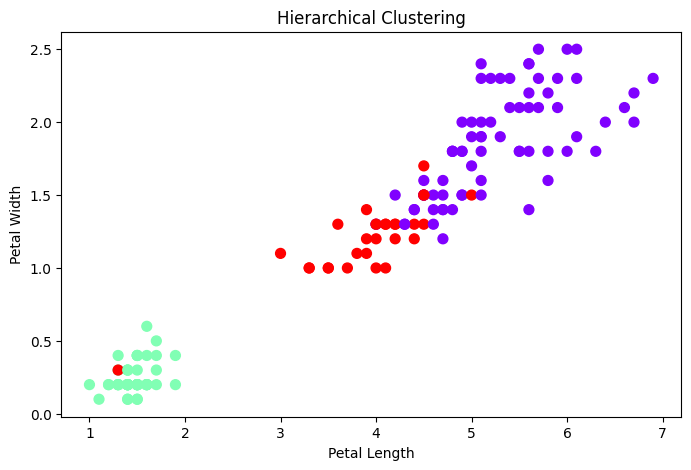

In [3]:

# PR9: Clustering Techniques

# * TASK 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram


# * TASK 2: Load inbuilt Iris dataset
data = load_iris()

df = pd.DataFrame(data.data, columns=data.feature_names)

print("First five rows:")
print(df.head())


# * TASK 3: Data preprocessing and feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("\nData standardized successfully!")


# * TASK 4: Elbow Method to find optimal clusters
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()


# * TASK 5: Implement K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means Cluster Results:")
print(df[["KMeans_Cluster"]].head())

print("\nNumber of data points in each K-Means cluster:")
print(df["KMeans_Cluster"].value_counts())


# * TASK 6: Visualize K-Means Clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    df["petal length (cm)"],
    df["petal width (cm)"],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    s=50
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clustering")
plt.show()


# * TASK 7: Create Dendrogram
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linked, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()


# * TASK 8: Implement Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("\nHierarchical Clustering Results:")
print(df[["Hierarchical_Cluster"]].head())

print("\nNumber of data points in each Hierarchical cluster:")
print(df["Hierarchical_Cluster"].value_counts())


# * TASK 9: Visualize Hierarchical Clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    df["petal length (cm)"],
    df["petal width (cm)"],
    c=df["Hierarchical_Cluster"],
    cmap="rainbow",
    s=50
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Hierarchical Clustering")
plt.show()



